que son las imagenes, transformaciones, para que sirven los filtros, deteccion de caracteristicas, principales filtros para que sirven, metodos de la clase pasada,


(np.float64(-0.5), np.float64(258.5), np.float64(193.5), np.float64(-0.5))

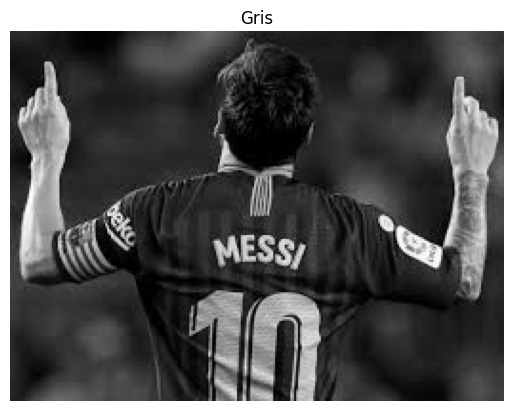

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("/content/descarga (2).jpg")
img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float32)

plt.imshow(img_gray, cmap='gray')
plt.title("Gris")
plt.axis("off")

### Suavizado Gaussiano (implementación manual)

Se construye manualmente un kernel Gaussiano a partir de la fórmula:

G(x,y) = (1 / 2πσ²) e^(-(x² + y²) / 2σ²)

Luego se aplica este kernel recorriendo la imagen píxel por píxel (convolución manual).

Este paso es fundamental para eliminar ruido antes de calcular los bordes.

(np.float64(-0.5), np.float64(258.5), np.float64(193.5), np.float64(-0.5))

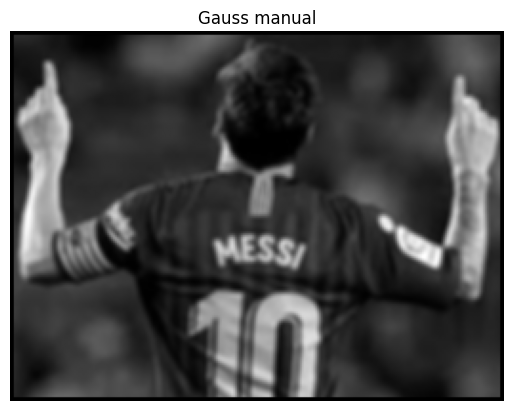

In [2]:
def gauss_kernel(size, sigma):
    k = size//2
    kernel = np.zeros((size,size))
    for i in range(-k, k+1):
        for j in range(-k, k+1):
            kernel[i+k,j+k] = np.exp(-(i**2+j**2)/(2*sigma**2))
    kernel = kernel / kernel.sum()
    return kernel

def aplicar_filtro(img, kernel):
    k = kernel.shape[0]//2
    h,w = img.shape
    out = np.zeros_like(img)

    for i in range(k, h-k):
        for j in range(k, w-k):
            region = img[i-k:i+k+1, j-k:j+k+1]
            out[i,j] = np.sum(region * kernel)
    return out

sigma = 1.4
kernel = gauss_kernel(5, sigma)
suavizada = aplicar_filtro(img_gray, kernel)

plt.imshow(suavizada, cmap='gray')
plt.title("Gauss manual")
plt.axis("off")

### Cálculo del gradiente con operadores Sobel

Se aplican los filtros Sobel en X y en Y sobre la imagen suavizada.

Esto permite obtener:
- Gx: cambios de intensidad horizontales (bordes verticales)
- Gy: cambios de intensidad verticales (bordes horizontales)

Con ambos se calcula:
- Magnitud del gradiente
- Dirección del gradiente

In [9]:
Sx = np.array([[-1,0,1],
               [-2,0,2],
               [-1,0,1]])

Sy = np.array([[-1,-2,-1],
               [0,0,0],
               [1,2,1]])

Gx = aplicar_filtro(suavizada, Sx)
Gy = aplicar_filtro(suavizada, Sy)

magnitud = np.sqrt(Gx**2 + Gy**2)
angulo = np.arctan2(Gy, Gx)

magnitud, angulo

(array([[  0.      ,   0.      ,   0.      , ...,   0.      ,   0.      ,
           0.      ],
        [  0.      ,  58.750202, 131.36946 , ..., 165.86687 ,  73.11893 ,
           0.      ],
        [  0.      , 128.46117 , 169.76027 , ..., 221.79333 , 161.97853 ,
           0.      ],
        ...,
        [  0.      , 106.32281 , 138.52039 , ..., 268.65076 , 200.7591  ,
           0.      ],
        [  0.      ,  47.118046, 103.31795 , ..., 199.54495 ,  89.56408 ,
           0.      ],
        [  0.      ,   0.      ,   0.      , ...,   0.      ,   0.      ,
           0.      ]], dtype=float32),
 array([[ 0.        ,  0.        ,  0.        , ...,  0.        ,
          0.        ,  0.        ],
        [ 0.        ,  0.7853982 ,  1.2490457 , ...,  1.8996724 ,
          2.3561945 ,  0.        ],
        [ 0.        ,  0.3103983 ,  0.76618856, ...,  2.3757842 ,
          2.8245409 ,  0.        ],
        ...,
        [ 0.        , -0.32627717, -0.80968565, ..., -2.351141  ,
         

### Supresión de no máximos

En esta etapa se afinan los bordes.

Para cada píxel, se observa la dirección del gradiente y se compara su magnitud con la de sus vecinos en esa dirección.

Si no es un máximo local, se elimina (se pone en 0).

Esto reduce los bordes gruesos a líneas finas.

(np.float64(-0.5), np.float64(258.5), np.float64(193.5), np.float64(-0.5))

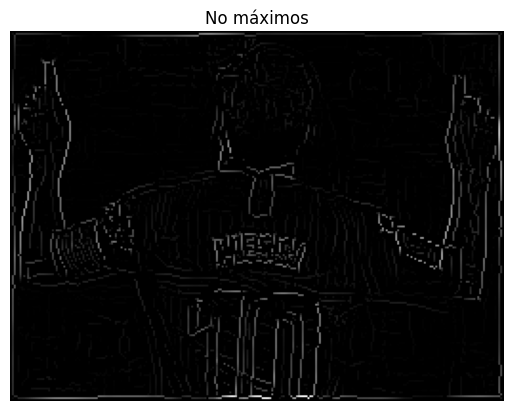

In [4]:
def no_maximos(mag, ang):
    h,w = mag.shape
    out = np.zeros((h,w))
    ang = ang * 180 / np.pi
    ang[ang<0] += 180

    for i in range(1,h-1):
        for j in range(1,w-1):
            q = 255
            r = 255

            # Dirección
            if (0 <= ang[i,j] < 22.5) or (157.5 <= ang[i,j] <= 180):
                q = mag[i, j+1]
                r = mag[i, j-1]
            elif (22.5 <= ang[i,j] < 67.5):
                q = mag[i+1, j-1]
                r = mag[i-1, j+1]
            elif (67.5 <= ang[i,j] < 112.5):
                q = mag[i+1, j]
                r = mag[i-1, j]
            elif (112.5 <= ang[i,j] < 157.5):
                q = mag[i-1, j-1]
                r = mag[i+1, j+1]

            if (mag[i,j] >= q) and (mag[i,j] >= r):
                out[i,j] = mag[i,j]
            else:
                out[i,j] = 0
    return out

nms = no_maximos(magnitud, angulo)
plt.imshow(nms, cmap='gray')
plt.title("No máximos")
plt.axis("off")

### Doble umbral

Se aplican dos umbrales:

- Umbral alto: identifica bordes fuertes
- Umbral bajo: identifica bordes débiles

Los bordes fuertes se conservan directamente.
Los débiles quedan marcados para evaluarse en la etapa de histéresis.

In [5]:
t_alto = 80
t_bajo = 30

fuertes = (nms >= t_alto)
debil = ((nms >= t_bajo) & (nms < t_alto))

res = np.zeros_like(nms)
res[fuertes] = 255
res[debil] = 75

### Histéresis

Los píxeles débiles se analizan:

Si un píxel débil está conectado a uno fuerte en su vecindad, se convierte en borde fuerte.

Si no, se elimina.

Esto permite conservar bordes reales que no eran tan intensos pero sí continuos.

(np.float64(-0.5), np.float64(258.5), np.float64(193.5), np.float64(-0.5))

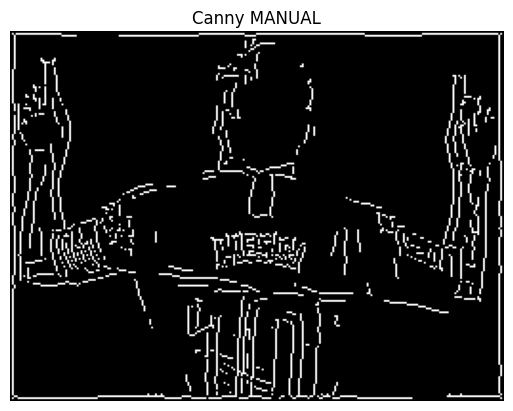

In [6]:
h,w = res.shape

for i in range(1,h-1):
    for j in range(1,w-1):
        if res[i,j] == 75:
            if np.any(res[i-1:i+2, j-1:j+2] == 255):
                res[i,j] = 255
            else:
                res[i,j] = 0

plt.imshow(res, cmap='gray')
plt.title("Canny MANUAL")
plt.axis("off")

### Aplicación del detector de Canny con OpenCV

Se utiliza la función `cv2.Canny`, que implementa internamente todas las etapas del algoritmo de forma optimizada y precisa.

Este resultado se utilizará para comparar con la implementación manual.

(np.float64(-0.5), np.float64(258.5), np.float64(193.5), np.float64(-0.5))

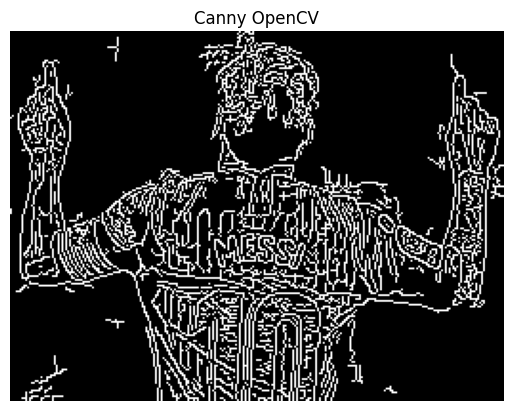

In [7]:
canny_cv = cv2.Canny(img_gray.astype(np.uint8), 30, 80)

plt.imshow(canny_cv, cmap='gray')
plt.title("Canny OpenCV")
plt.axis("off")

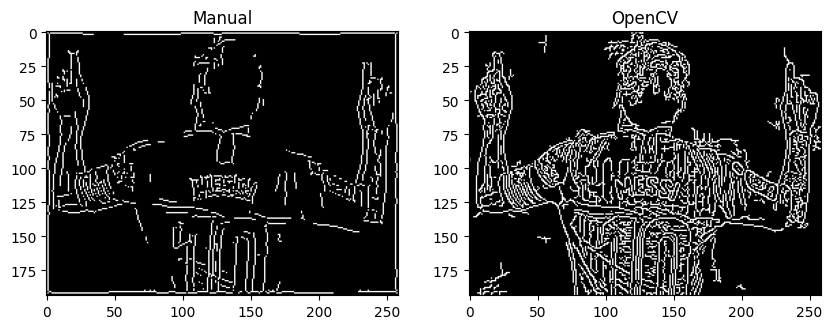

In [8]:
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(res, cmap='gray')
plt.title("Manual")

plt.subplot(1,2,2)
plt.imshow(canny_cv, cmap='gray')
plt.title("OpenCV")

plt.show()

## Conclusión

La implementación manual del detector de Canny permite comprender en detalle cada una de las etapas del algoritmo: suavizado, cálculo del gradiente, supresión de no máximos, doble umbral e histéresis.

Sin embargo, al comparar con la implementación de OpenCV, se observa que:

- OpenCV detecta más bordes y con mayor continuidad
- Los bordes son más finos y precisos
- Se conservan mejor los detalles de la imagen

Esto se debe a que OpenCV utiliza optimizaciones internas, mejor manejo de los ángulos, interpolaciones más precisas y un tratamiento más robusto del ruido.

El experimento demuestra cómo cada etapa del algoritmo influye directamente en la calidad final de los bordes detectados y cómo los parámetros como σ (sigma) y los umbrales afectan el resultado.